# Ridge and the Lasso: Coefficients and Error as $\lambda$ Changes

**DSAI 621 — Week 2.** You fit ridge regression and the lasso over a grid of $\lambda$ values
and watch two things change: the coefficients, and the training and test error.

The first time something new appears, the notebook gives you all of the code. When a step
repeats something you've already seen, you write it, and the cell says `# TODO`. Short
exercises marked **E1**, **E2**, … ask you to stop and look at what you just made.

In this notebook, as in ISL 6.2, the two methods minimize

$$\text{ridge: } \mathrm{RSS} + \lambda\sum_{j=1}^p\beta_j^2, \qquad \text{lasso: } \mathrm{RSS} + \lambda\sum_{j=1}^p|\beta_j| .$$

scikit-learn calls the tuning parameter `alpha`. For `Ridge`, `alpha` is exactly ISL's $\lambda$.
`Lasso` divides the RSS by $2n$, so its `alpha` is ISL's $\lambda / (2n)$. The two methods'
`alpha` values are on different scales, so compare their *curves*, not their `alpha` numbers.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_diabetes
from sklearn.linear_model import Lasso, LassoCV, LinearRegression, Ridge, RidgeCV
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

rng = np.random.default_rng(621)

---
## 1. The data

The diabetes data (Efron et al., 2004) are a standard regression example, and they ship with
scikit-learn. For $n = 442$ patients, they record $p = 10$ baseline predictors: age, sex, body
mass index (`bmi`), blood pressure (`bp`), and six blood serum measurements (`s1`–`s6`). The
response is a measure of disease progression one year later.

We split the data in half, train and test, and standardize the predictors using the training
set's means and standard deviations. Ridge and the lasso penalize every coefficient by the same
amount, so the predictors need to be on a common scale (ISL 6.2.1).

In [2]:
diabetes = load_diabetes(as_frame=True, scaled=False)
X, y = diabetes.data, diabetes.target
names = X.columns.tolist()

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.5, random_state=621)
scaler = StandardScaler().fit(X_tr)
X_tr, X_te = scaler.transform(X_tr), scaler.transform(X_te)

print(f"training set: {X_tr.shape[0]} observations, test set: {X_te.shape[0]}, p = {X_tr.shape[1]}")
X.head()

training set: 221 observations, test set: 221, p = 10


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0


### Least squares first

Ordinary least squares is the $\lambda = 0$ end of both methods, so fit it first as a baseline.

In [3]:
def mse(model, X, y):
    return np.mean((y - model.predict(X)) ** 2)

ols = LinearRegression().fit(X_tr, y_tr)
print(f"OLS training MSE: {mse(ols, X_tr, y_tr):7.0f}")
print(f"OLS test MSE:     {mse(ols, X_te, y_te):7.0f}")
pd.Series(ols.coef_, index=names).round(1)

OLS training MSE:    2798
OLS test MSE:        3053


age    -2.1
sex   -12.6
bmi    25.6
bp     17.1
s1    -43.2
s2     30.3
s3      6.5
s4     12.9
s5     29.7
s6      4.8
dtype: float64

**E1.** How much larger is the test MSE than the training MSE? With 221 training observations
and 10 predictors, would you expect least squares to overfit badly?

---
## 2. Ridge regression

Fit ridge for 81 values of $\lambda$, spaced evenly on a log scale from $10^{-2}$ to $10^{4}$.
For each one, save the coefficients and the training and test MSE.

In [4]:
ridge_alphas = np.logspace(-2, 4, 81)

ridge_coefs, ridge_train, ridge_test = [], [], []
for a in ridge_alphas:
    model = Ridge(alpha=a).fit(X_tr, y_tr)
    ridge_coefs.append(model.coef_)
    ridge_train.append(mse(model, X_tr, y_tr))
    ridge_test.append(mse(model, X_te, y_te))
ridge_coefs = np.array(ridge_coefs)     # one row per lambda, one column per predictor

### Coefficient paths

The next two functions draw what we just computed, and you'll reuse them for the lasso.
`plot_paths` draws one line per predictor and labels each line at its left end, so you can
identify lines without relying on colour. `plot_errors` draws training and test MSE and marks
the $\lambda$ with the lowest test MSE.

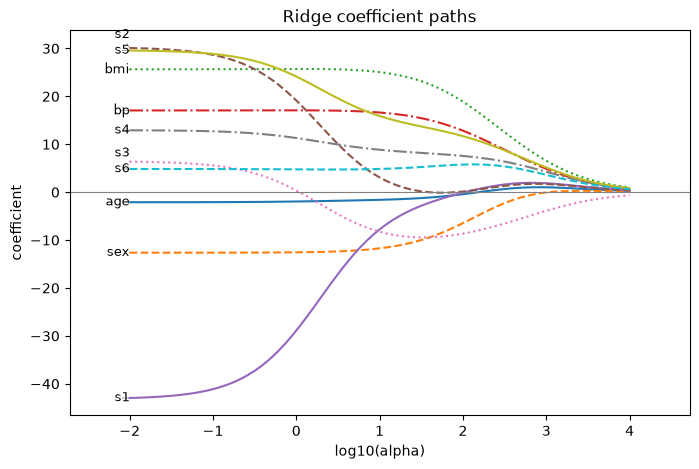

In [5]:
STYLES = ["-", "--", ":", "-."]

def plot_paths(alphas, coefs, names, title, ax=None, label_top=None):
    "One line per coefficient against log10(alpha); label_top labels only the largest few."
    ax = ax or plt.subplots(figsize=(8, 5))[1]
    start = coefs[0]
    show = np.argsort(-np.abs(start))[:label_top] if label_top else range(len(names))
    for j in range(coefs.shape[1]):
        ax.plot(np.log10(alphas), coefs[:, j], STYLES[j % 4], lw=1.5)
    # nudge labels apart so that lines starting close together stay readable
    gap = 0.045 * (coefs.max() - coefs.min())
    ypos = {}
    for j in sorted(show, key=lambda j: start[j]):
        ypos[j] = max(start[j], max(ypos.values(), default=-np.inf) + gap)
    for j in show:
        ax.annotate(names[j], (np.log10(alphas[0]), start[j]), xytext=(np.log10(alphas[0]), ypos[j]),
                    textcoords="data", ha="right", va="center", fontsize=9,
                    arrowprops=dict(arrowstyle="-", color="grey", lw=0.5, shrinkA=8, shrinkB=0))
    ax.axhline(0, color="grey", lw=0.8)
    ax.set(xlabel="log10(alpha)", ylabel="coefficient", title=title)
    ax.margins(x=0.12)
    return ax

def plot_errors(alphas, train, test, title, ax=None):
    "Training and test MSE against log10(alpha); marks the alpha with the lowest test MSE."
    ax = ax or plt.subplots(figsize=(8, 4))[1]
    ax.plot(np.log10(alphas), train, "-", color="black", label="training MSE")
    ax.plot(np.log10(alphas), test, "--", color="tab:red", label="test MSE")
    k = int(np.argmin(test))
    ax.plot(np.log10(alphas[k]), test[k], "v", color="tab:red", ms=9,
            label=f"lowest test MSE: {test[k]:.0f} at alpha = {alphas[k]:.3g}")
    ax.set(xlabel="log10(alpha)", ylabel="MSE", title=title)
    ax.legend()
    return ax

plot_paths(ridge_alphas, ridge_coefs, names, "Ridge coefficient paths")
plt.show()

**E2.** Which coefficients are largest when $\lambda$ is small? Do they match the OLS coefficients
above? Does any coefficient become exactly zero before the right-hand end?

**E3.** Find a coefficient that changes sign as $\lambda$ grows. Look at the serum measurements
`s1`–`s6`: why might correlated predictors behave this way?

In [6]:
print(pd.DataFrame(X_tr, columns=names)[["s1", "s2", "s3", "s4"]].corr().round(2))

      s1    s2    s3    s4
s1  1.00  0.90  0.01  0.55
s2  0.90  1.00 -0.23  0.66
s3  0.01 -0.23  1.00 -0.75
s4  0.55  0.66 -0.75  1.00


### Training and test error

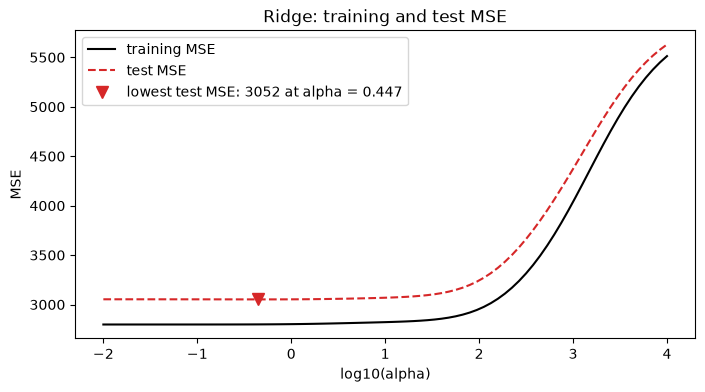

In [7]:
plot_errors(ridge_alphas, ridge_train, ridge_test, "Ridge: training and test MSE")
plt.show()

**E4.** Why does the training MSE only ever go up as $\lambda$ grows? (Hint: what does least
squares minimize?)

**E5.** How much lower is ridge's best test MSE than the OLS test MSE? Given your answer to E1,
is that surprising?

---
## 3. The lasso

Now repeat Section 2 with `Lasso`. Use the grid below, which runs up to the smallest `alpha` that
sets every coefficient to zero. Also record the number of non-zero coefficients for each
`alpha`.

In [8]:
lasso_alphas = np.logspace(-2, np.log10(50), 81)

lasso_coefs, lasso_train, lasso_test, lasso_nonzero = [], [], [], []
# TODO: loop over lasso_alphas, fit Lasso(alpha=a), and append to the four lists
lasso_coefs = np.array(lasso_coefs)

In [9]:
# TODO: plot the lasso coefficient paths, then the training and test MSE

**E6.** Read the coefficient paths from right to left, from large $\lambda$ to small. In what
order do the predictors enter the model? Which predictor would the lasso keep if you could only
have one?

**E7.** How does the shape of a lasso path differ from a ridge path? Describe what happens to a
lasso coefficient once it reaches zero.

In [10]:
# TODO: at the alpha with the lowest lasso test MSE, how many predictors are non-zero,
# and which predictors has the lasso dropped?

**E8.** Compare the best test MSE of OLS, ridge and the lasso. With $p = 10$ and $n = 221$,
does either method help much?

---
## 4. Many more predictors

Shrinkage matters most when the model has many predictors relative to $n$. Add every square and
every pairwise product of the 10 predictors (age², bmi × bp, …). `PolynomialFeatures` builds
these columns. We drop sex², because `sex` takes only the values 1 and 2, so sex² is an exact
linear function of `sex`. That leaves $p = 64$ predictors for the same 221 training observations.
We standardize again, because squares and products are on new scales.

In [11]:
poly = PolynomialFeatures(degree=2, include_bias=False).fit(X_tr)
names2 = poly.get_feature_names_out(names).tolist()
keep = [j for j, name in enumerate(names2) if name != "sex^2"]
names2 = [names2[j] for j in keep]
X2_tr, X2_te = poly.transform(X_tr)[:, keep], poly.transform(X_te)[:, keep]
scaler2 = StandardScaler().fit(X2_tr)
X2_tr, X2_te = scaler2.transform(X2_tr), scaler2.transform(X2_te)

ols2 = LinearRegression().fit(X2_tr, y_tr)
print(f"p = {X2_tr.shape[1]}")
print(f"OLS training MSE: {mse(ols2, X2_tr, y_tr):7.0f}")
print(f"OLS test MSE:     {mse(ols2, X2_te, y_te):7.0f}")

p = 64
OLS training MSE:    2078
OLS test MSE:        3909


**E9.** Compare these numbers with the 10-predictor OLS fit in Section 1. Why did the training
MSE go down while the test MSE went up?

Now fit ridge and the lasso on the 64 predictors, using the grids below. The lasso needs
more iterations to converge at small `alpha`, so pass `max_iter=100_000` to `Lasso`. Plot
the training and test MSE for each method. Plotting the coefficient paths is optional: with 64
lines, pass `label_top=6` to `plot_paths` to label only the six largest.

In [12]:
ridge2_alphas = np.logspace(-1, 5, 61)
lasso2_alphas = np.logspace(-2, np.log10(50), 61)

# TODO: fit ridge over ridge2_alphas and the lasso over lasso2_alphas on X2_tr, recording
# the coefficients, training MSE and test MSE (and, for the lasso, the number of non-zero
# coefficients)

In [13]:
# TODO: plot the training and test MSE for ridge and for the lasso (side by side is nice:
# fig, ax = plt.subplots(1, 2) and pass ax=ax[0], ax=ax[1])

**E10.** Now there's a clear U shape in test MSE. On each plot, which side of the U is high
variance, and which is high bias?

**E11.** Make a small table of the best test MSE for OLS, ridge and the lasso with $p = 64$. How
many of the 64 predictors does the lasso use at its best `alpha`? Which ones are they?

In [14]:
# TODO

---
## 5. Choosing $\lambda$ without the test set

So far we picked the best $\lambda$ by looking at the test set. That's cheating: the test set is
then part of the fitting, and its MSE is no longer an honest estimate of how the model does on
new data. In practice we choose $\lambda$ by $K$-fold cross-validation on the training set
(ISL 5.1.3, 6.2.3). `RidgeCV` and `LassoCV` do this for a whole grid of `alpha` values.

In [15]:
ridge_cv = RidgeCV(alphas=ridge2_alphas, cv=10).fit(X2_tr, y_tr)
print(f"ridge: CV chose alpha = {ridge_cv.alpha_:.3g}, test MSE {mse(ridge_cv, X2_te, y_te):.0f}")

ridge: CV chose alpha = 79.4, test MSE 3192


In [16]:
# TODO: do the same with LassoCV (pass max_iter=100_000), and also print the number
# of non-zero coefficients

**E12.** How close are the cross-validated choices of `alpha` to the ones that minimized test MSE
in Section 4? How much test MSE did you give up by not peeking?

---
## 6. Wrap-up questions

**Q1.** In your own words, why can the lasso set a coefficient exactly to zero while ridge
can't? (ISL Figure 6.7 may help.)

**Q2.** Suppose a colleague fits the lasso on unstandardized predictors where one predictor is
measured in dollars and another in thousands of dollars. What goes wrong?

**Q3.** In Section 1, shrinkage barely helped; in Section 4 it helped a lot. What changed, and
what does that tell you about when to reach for ridge or the lasso?